¡Hola, Mara!

Mi nombre es Tonatiuh Cruz. Me complace revisar tu proyecto hoy.

Al identificar cualquier error inicialmente, simplemente los destacaré. Te animo a localizar y abordar los problemas de forma independiente como parte de tu preparación para un rol como data-analyst. En un entorno profesional, tu líder de equipo seguiría un enfoque similar. Si encuentras la tarea desafiante, proporcionaré una pista más específica en la próxima iteración.
Encontrarás mis comentarios a continuación - **por favor no los muevas, modifiques o elimines**.

Puedes encontrar mis comentarios en cajas verdes, amarillas o rojas como esta:

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Éxito. Todo está hecho correctamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Observaciones. Algunas recomendaciones.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Necesita corrección. El bloque requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios en rojo.
</div>

Puedes responderme utilizando esto:

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante.</b> <a class="tocSkip"></a>
</div>

In [3]:
import pandas as pd

# Cargar los tres archivos del proyecto
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv')
orders     = pd.read_csv('/datasets/orders_us.csv')
visits     = pd.read_csv('/datasets/visits_us.csv')

print(hypotheses.head())

           Hypothesis;Reach;Impact;Confidence;Effort
0  Add two new channels for attracting traffic. T...
1  Launch your own delivery service. This will sh...
2  Add product recommendation blocks to the store...
3  Change the category structure. This will incre...
4  Change the background color on the main page. ...


In [5]:
print(hypotheses.columns.tolist())

['Hypothesis;Reach;Impact;Confidence;Effort']


In [6]:
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv', sep=';')

print(hypotheses.columns.tolist())

['Hypothesis', 'Reach', 'Impact', 'Confidence', 'Effort']


In [8]:
print(ice[['Hypothesis', 'Impact', 'Confidence', 'Effort', 'ICE']])

                                          Hypothesis  Impact  Confidence  \
1  Launch a promotion that gives users discounts ...       9           9   
2  Add two new channels for attracting traffic. T...      10           8   
3  Add a subscription form to all the main pages....       7           8   
4  Show banners with current offers and sales on ...       3           8   
5  Add product recommendation blocks to the store...       3           7   
6  Launch your own delivery service. This will sh...       5           4   
7  Add a customer review page. This will increase...       2           2   
8  Change the category structure. This will incre...       3           3   
9  Change the background color on the main page. ...       1           1   

   Effort        ICE  
1       5  16.200000  
2       6  13.333333  
3       5  11.200000  
4       3   8.000000  
5       3   7.000000  
6      10   2.000000  
7       3   1.333333  
8       8   1.125000  
9       1   1.000000  


In [8]:
print(ice[['Hypothesis', 'Impact', 'Confidence', 'Effort', 'ICE']])

                                          Hypothesis  Impact  Confidence  \
1  Launch a promotion that gives users discounts ...       9           9   
2  Add two new channels for attracting traffic. T...      10           8   
3  Add a subscription form to all the main pages....       7           8   
4  Show banners with current offers and sales on ...       3           8   
5  Add product recommendation blocks to the store...       3           7   
6  Launch your own delivery service. This will sh...       5           4   
7  Add a customer review page. This will increase...       2           2   
8  Change the category structure. This will incre...       3           3   
9  Change the background color on the main page. ...       1           1   

   Effort        ICE  
1       5  16.200000  
2       6  13.333333  
3       5  11.200000  
4       3   8.000000  
5       3   7.000000  
6      10   2.000000  
7       3   1.333333  
8       8   1.125000  
9       1   1.000000  


La hipótesis #1 es la más prioritaria con ICE de 16.2 — lanzar una promoción con descuentos tiene alto impacto y confianza con un esfuerzo moderado.
La hipótesis #9 es la menos prioritaria con ICE de 1.0 — cambiar el color de fondo tiene poco impacto y poca confianza.

In [9]:
# Calcular score RICE
hypotheses['RICE'] = hypotheses['Reach'] * hypotheses['Impact'] * hypotheses['Confidence'] / hypotheses['Effort']

# Ordenar de mayor a menor
rice = hypotheses.sort_values('RICE', ascending=False).reset_index(drop=True)
rice.index += 1

# Mostrar resultado
print(rice[['Hypothesis', 'Reach', 'Impact', 'Confidence', 'Effort', 'RICE']])

                                          Hypothesis  Reach  Impact  \
1  Add a subscription form to all the main pages....     10       7   
2  Add product recommendation blocks to the store...      8       3   
3  Add two new channels for attracting traffic. T...      3      10   
4  Show banners with current offers and sales on ...      5       3   
5  Launch a promotion that gives users discounts ...      1       9   
6  Change the category structure. This will incre...      8       3   
7  Launch your own delivery service. This will sh...      2       5   
8  Add a customer review page. This will increase...      3       2   
9  Change the background color on the main page. ...      3       1   

   Confidence  Effort   RICE  
1           8       5  112.0  
2           7       3   56.0  
3           8       6   40.0  
4           8       3   40.0  
5           9       5   16.2  
6           3       8    9.0  
7           4      10    4.0  
8           2       3    4.0  
9         

La principal diferencia entre ICE y RICE es que RICE incorpora el Reach
(alcance), lo que cambia significativamente la priorización:

 "Launch a promotion" cayó del #1 al #5 porque tiene Reach muy bajo (1).
  Aunque su impacto y confianza son altos, solo afecta a muy pocos usuarios,
  por lo que RICE la penaliza fuertemente.

"Add subscription form" subió del #3 al #1 porque tiene el Reach más alto
  (10). Llega a la mayor cantidad de usuarios posible, lo que la hace la
  hipótesis más valiosa cuando consideramos el alcance.

"Add product recommendation blocks" subió del #5 al #2 por su Reach de 8,
  que compensa su Impact relativamente bajo.

Conclusión: ICE puede sobreestimar hipótesis que tienen gran impacto pero
llegan a pocos usuarios. RICE es más completo porque considera cuántas
personas se verán beneficiadas, no solo qué tan buena es la idea en sí.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Perfecto, Mara. Excelente trabajo aplicando, analizando y comparando los frameworks RICE e ICE. Solamente para complementar puedes hacer un análisis de los hallazgos para la priorización de las hipótesis.  </div>

In [10]:
import pandas as pd

orders = pd.read_csv('/datasets/orders_us.csv', sep=';')
visits = pd.read_csv('/datasets/visits_us.csv', sep=';')

print("ORDERS:")
print(orders.head())
print("\nVISITS:")
print(visits.head())

ORDERS:
  transactionId,visitorId,date,revenue,group
0    3667963787,3312258926,2019-08-15,30.4,B
1    2804400009,3642806036,2019-08-15,15.2,B
2    2961555356,4069496402,2019-08-15,10.2,A
3   3797467345,1196621759,2019-08-15,155.1,B
4    2282983706,2322279887,2019-08-15,40.5,B

VISITS:
  date,group,visits
0  2019-08-01,A,719
1  2019-08-02,A,619
2  2019-08-03,A,507
3  2019-08-04,A,717
4  2019-08-05,A,756


In [11]:
orders = pd.read_csv('/datasets/orders_us.csv', sep=',')

print(orders.head())
print(orders.columns.tolist())

   transactionId   visitorId        date  revenue group
0     3667963787  3312258926  2019-08-15     30.4     B
1     2804400009  3642806036  2019-08-15     15.2     B
2     2961555356  4069496402  2019-08-15     10.2     A
3     3797467345  1196621759  2019-08-15    155.1     B
4     2282983706  2322279887  2019-08-15     40.5     B
['transactionId', 'visitorId', 'date', 'revenue', 'group']


In [13]:
visits = pd.read_csv('/datasets/visits_us.csv', sep=',')

print(visits.columns.tolist())

['date', 'group', 'visits']


In [14]:
# Convertir fecha a formato fecha
orders['date'] = pd.to_datetime(orders['date'])
visits['date'] = pd.to_datetime(visits['date'])

# Buscar usuarios que aparecen en ambos grupos (anomalía)
users_per_group = orders.groupby('visitorId')['group'].nunique()
duplicated_users = users_per_group[users_per_group > 1].index

print(f"Usuarios en ambos grupos: {len(duplicated_users)}")

# Eliminarlos
orders = orders[~orders['visitorId'].isin(duplicated_users)]

print(f"Pedidos tras limpieza: {len(orders)}")

Usuarios en ambos grupos: 58
Pedidos tras limpieza: 1016


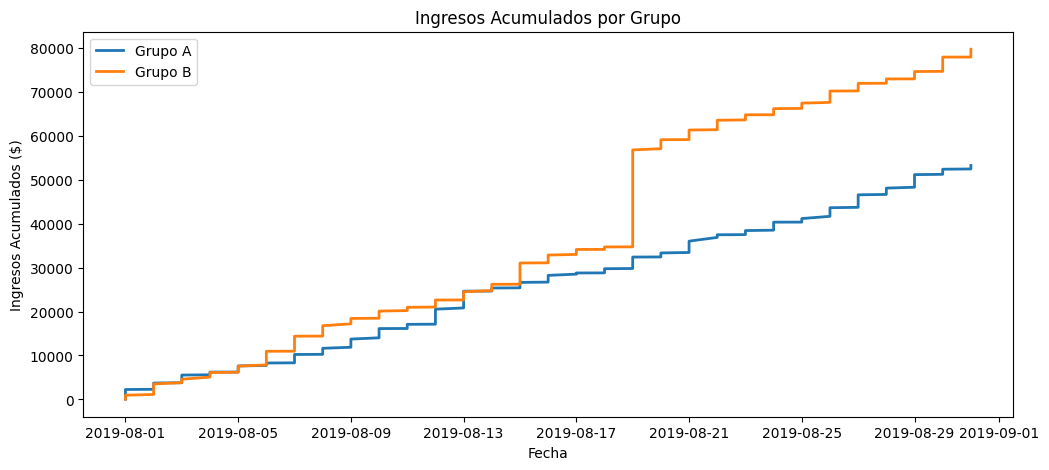

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

for group in ['A', 'B']:
    g = (orders[orders['group'] == group]
         .sort_values('date')
         .assign(cum_rev=lambda d: d['revenue'].cumsum()))
    ax.plot(g['date'], g['cum_rev'], label=f'Grupo {group}', linewidth=2)

ax.set_title('Ingresos Acumulados por Grupo')
ax.set_xlabel('Fecha')
ax.set_ylabel('Ingresos Acumulados ($)')
ax.legend()
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Perfecto, gran trabajo con el desarrollo y análisis del gráfico del tamaña de pedido acumulado por grupos. Ya solamente para complementar puedes realizar el ingreso acumulado desagregado por cada grupo


El grupo B acumula más ingresos que el grupo A a lo largo del período.
Hay un salto brusco alrededor del 20 de agosto en el grupo B, probablemente
causado por uno o varios pedidos de valor muy alto (anomalías). Este salto
distorsiona los resultados y se debe analizar por separado.

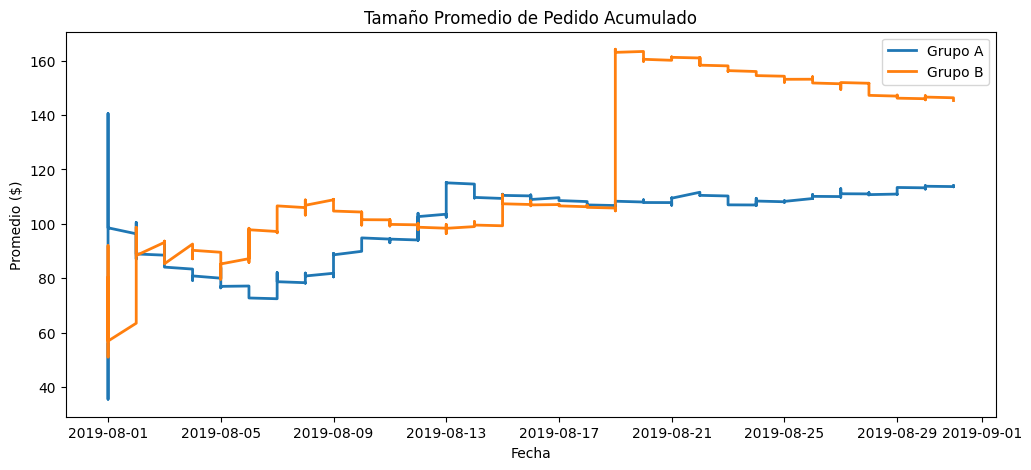

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))

for group in ['A', 'B']:
    g = (orders[orders['group'] == group]
         .sort_values('date')
         .reset_index(drop=True))
    g['cum_orders']  = range(1, len(g) + 1)
    g['cum_revenue'] = g['revenue'].cumsum()
    g['avg_order']   = g['cum_revenue'] / g['cum_orders']
    ax.plot(g['date'], g['avg_order'], label=f'Grupo {group}', linewidth=2)

ax.set_title('Tamaño Promedio de Pedido Acumulado')
ax.set_xlabel('Fecha')
ax.set_ylabel('Promedio ($)')
ax.legend()
plt.show()

Al inicio ambos grupos son inestables porque hay pocos datos.
A partir de mediados de agosto el grupo B muestra un promedio
significativamente más alto (~160$) debido al salto brusco detectado.
Al final del período B se estabiliza cerca de 150$ y A cerca de 110$.
Esto sugiere que hay pedidos atípicos de alto valor en B que inflan
el promedio — se necesita filtrar anomalías para confirmar si la
diferencia es real.

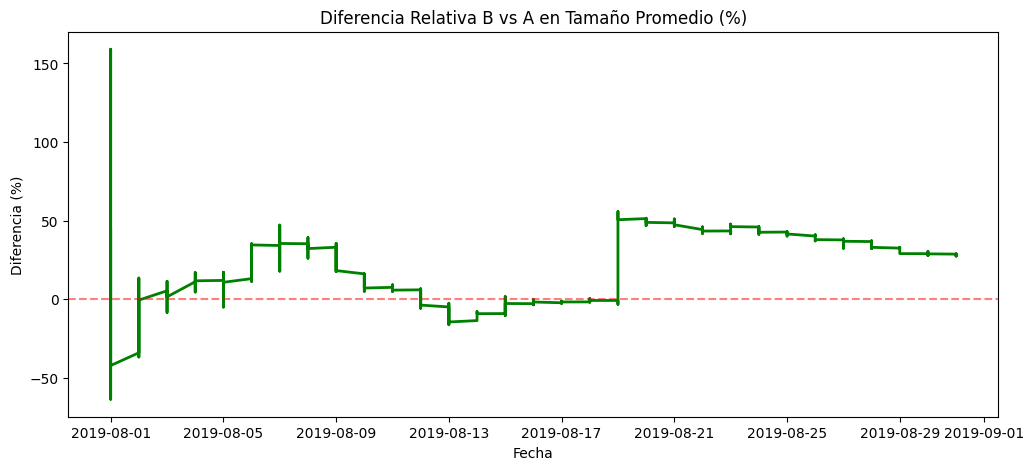

In [17]:
# Calcular promedio acumulado por grupo
cum = {}
for group in ['A', 'B']:
    g = (orders[orders['group'] == group]
         .sort_values('date')
         .reset_index(drop=True))
    g['cum_orders']  = range(1, len(g) + 1)
    g['cum_revenue'] = g['revenue'].cumsum()
    g['avg_order']   = g['cum_revenue'] / g['cum_orders']
    cum[group] = g[['date', 'avg_order']]

# Unir y calcular diferencia relativa
merged = pd.merge(
    cum['A'].rename(columns={'avg_order': 'A'}),
    cum['B'].rename(columns={'avg_order': 'B'}),
    on='date'
)
merged['rel_diff'] = (merged['B'] - merged['A']) / merged['A'] * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(merged['date'], merged['rel_diff'], linewidth=2, color='green')
ax.axhline(0, color='red', linestyle='--', alpha=0.5)
ax.set_title('Diferencia Relativa B vs A en Tamaño Promedio (%)')
ax.set_xlabel('Fecha')
ax.set_ylabel('Diferencia (%)')
plt.show()

La diferencia relativa se mantiene mayormente por encima de cero,
lo que indica que el grupo B tiene un tamaño promedio de pedido
más alto que el grupo A durante casi todo el período.
Sin embargo, hay un pico muy pronunciado alrededor del 20 de agosto
causado por los pedidos atípicos de alto valor en B. Una vez que
filtremos las anomalías veremos si esta diferencia se mantiene o
desaparece.

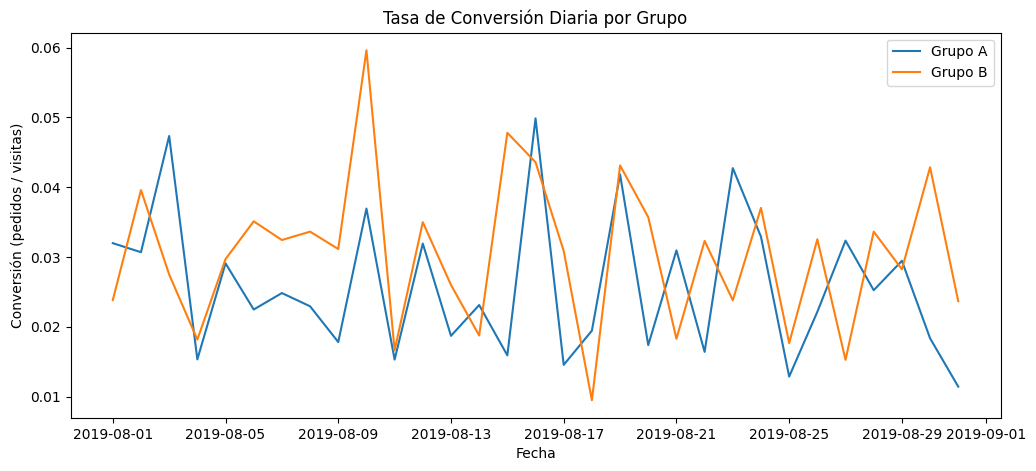

In [18]:
# Pedidos por día y grupo
daily_orders = (orders.groupby(['date', 'group'])
                .size().reset_index(name='orders'))

# Unir con visitas
daily = pd.merge(daily_orders, visits, on=['date', 'group'], how='outer').fillna(0)

# Calcular conversión
daily['conversion'] = daily['orders'] / daily['visits']

# Graficar
fig, ax = plt.subplots(figsize=(12, 5))
for group in ['A', 'B']:
    g = daily[daily['group'] == group].sort_values('date')
    ax.plot(g['date'], g['conversion'], label=f'Grupo {group}', linewidth=1.5)

ax.set_title('Tasa de Conversión Diaria por Grupo')
ax.set_xlabel('Fecha')
ax.set_ylabel('Conversión (pedidos / visitas)')
ax.legend()
plt.show()

El grupo B tiene una tasa de conversión generalmente más alta que el grupo A
durante la mayor parte del período. Ambas líneas son bastante volátiles día
a día, lo que es normal con pocos datos diarios.

El pico más alto del grupo B (~0.06) ocurre alrededor del 9 de agosto,
lo que puede indicar un día con muchos pedidos o pocas visitas.

En general, el grupo B convierte mejor que el grupo A, pero la diferencia
no es dramática — las líneas se cruzan varias veces. Se necesita una prueba
estadística para confirmar si la diferencia es real.

# Contar pedidos por usuario
orders_per_user = (orders.groupby(['visitorId', 'group'])
                   .size().reset_index(name='n_orders'))

fig, ax = plt.subplots(figsize=(10, 5))
for group in ['A', 'B']:
    g = orders_per_user[orders_per_user['group'] == group].reset_index(drop=True)
    ax.scatter(g.index, g['n_orders'], alpha=0.4, s=15, label=f'Grupo {group}')

ax.set_title('Pedidos por Usuario')
ax.set_xlabel('Usuario (índice)')
ax.set_ylabel('Número de pedidos')
ax.legend()
plt.show()

# Percentiles
for group in ['A', 'B']:
    g = orders_per_user[orders_per_user['group'] == group]['n_orders']
    print(f"Grupo {group} — percentil 95: {g.quantile(0.95):.0f} pedidos, percentil 99: {g.quantile(0.99):.0f} pedidos")

La mayoría de los usuarios hicieron solo 1 pedido durante el período.
El percentil 95 es 1 para ambos grupos, lo que significa que el 95% 
de los usuarios hizo máximo 1 pedido.
El percentil 99 es 3 para A y 2 para B, por lo que usuarios con más
de 3 pedidos se consideran anomalías y serán filtrados más adelante.

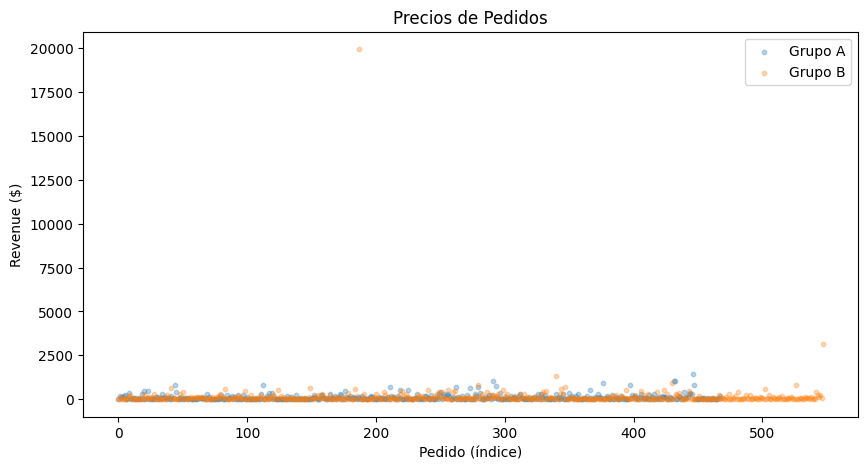

Grupo A — percentil 95: $385.63, percentil 99: $863.20
Grupo B — percentil 95: $425.79, percentil 99: $763.86


In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
for group in ['A', 'B']:
    g = orders[orders['group'] == group].reset_index(drop=True)
    ax.scatter(g.index, g['revenue'], alpha=0.3, s=10, label=f'Grupo {group}')

ax.set_title('Precios de Pedidos')
ax.set_xlabel('Pedido (índice)')
ax.set_ylabel('Revenue ($)')
ax.legend()
plt.show()

# Percentiles
for group in ['A', 'B']:
    g = orders[orders['group'] == group]['revenue']
    print(f"Grupo {group} — percentil 95: ${g.quantile(0.95):.2f}, percentil 99: ${g.quantile(0.99):.2f}")

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>



Muy buena forma de realizar este análisis para mostrar los precios por pedidos, para complementar puedes colocar número de pedidos por usuario

In [ ]:
La mayoría de los pedidos tienen precios bajos y concentrados cerca de cero.
Hay algunos puntos muy alejados hacia arriba (valores atípicos) que
representan pedidos de valor muy alto.

El percentil 99 es $863 para A y $764 para B. Pedidos por encima de
estos valores se consideran anomalías. Usaremos $863 como umbral general
para filtrar pedidos atípicos en ambos grupos antes de las pruebas
estadísticas.

In [22]:
from scipy import stats

# Conversión bruta por grupo
total_visits  = daily.groupby('group')['visits'].sum()
total_orders  = daily.groupby('group')['orders'].sum()

conv_a = total_orders['A'] / total_visits['A']
conv_b = total_orders['B'] / total_visits['B']

print(f"Conversión A: {conv_a:.4f}")
print(f"Conversión B: {conv_b:.4f}")
print(f"Diferencia relativa: {(conv_b - conv_a) / conv_a * 100:.2f}%")

# Prueba estadística sobre pedidos por usuario
a_orders = orders_per_user[orders_per_user['group'] == 'A']['n_orders']
b_orders = orders_per_user[orders_per_user['group'] == 'B']['n_orders']

stat, p = stats.mannwhitneyu(a_orders, b_orders, alternative='two-sided')
print(f"\nPrueba conversión (datos brutos):")
print(f"p-value: {p:.4f}")
print("Significativa" if p < 0.05 else "No significativa")

# Prueba sobre revenue
a_rev = orders[orders['group'] == 'A']['revenue']
b_rev = orders[orders['group'] == 'B']['revenue']

stat2, p2 = stats.mannwhitneyu(a_rev, b_rev, alternative='two-sided')
print(f"\nPrueba tamaño de pedido (datos brutos):")
print(f"p-value: {p2:.4f}")
print("Significativa" if p2 < 0.05 else "No significativa")

Conversión A: 0.0250
Conversión B: 0.0290
Diferencia relativa: 15.98%

Prueba conversión (datos brutos):
p-value: 0.5880
No significativa

Prueba tamaño de pedido (datos brutos):
p-value: 0.8622
No significativa


Con datos en bruto:
- La conversión de B es 15.98% mayor que A (0.029 vs 0.025).
  Aunque parece una diferencia importante, la prueba estadística
  dice que NO es significativa (p=0.588 > 0.05). Esto significa
  que la diferencia puede ser por azar.

- El tamaño promedio de pedido tampoco muestra diferencia
  significativa (p=0.862 > 0.05).

Conclusión: con datos en bruto no podemos afirmar que haya
una diferencia real entre los grupos. Los valores atípicos
están distorsionando los resultados.

In [23]:
# Definir umbrales de anomalías
umbral_pedidos = 3   # percentil 99 de pedidos por usuario
umbral_revenue = 863 # percentil 99 de revenue

# Filtrar usuarios y pedidos atípicos
usuarios_normales = orders_per_user[orders_per_user['n_orders'] <= umbral_pedidos]['visitorId']
orders_f = orders[
    (orders['visitorId'].isin(usuarios_normales)) &
    (orders['revenue'] <= umbral_revenue)
]

print(f"Pedidos tras filtrado: {len(orders_f)}  (eliminados: {len(orders) - len(orders_f)})")

# Pedidos por usuario filtrado
orders_pu_f = orders_f.groupby(['visitorId', 'group']).size().reset_index(name='n_orders')

# Prueba conversión filtrada
a_ord_f = orders_pu_f[orders_pu_f['group'] == 'A']['n_orders']
b_ord_f = orders_pu_f[orders_pu_f['group'] == 'B']['n_orders']

stat3, p3 = stats.mannwhitneyu(a_ord_f, b_ord_f, alternative='two-sided')
print(f"\nPrueba conversión (datos filtrados):")
print(f"p-value: {p3:.4f}")
print("Significativa" if p3 < 0.05 else "No significativa")

# Prueba revenue filtrado
a_rev_f = orders_f[orders_f['group'] == 'A']['revenue']
b_rev_f = orders_f[orders_f['group'] == 'B']['revenue']

stat4, p4 = stats.mannwhitneyu(a_rev_f, b_rev_f, alternative='two-sided')
print(f"\nPrueba tamaño de pedido (datos filtrados):")
print(f"p-value: {p4:.4f}")
print("Significativa" if p4 < 0.05 else "No significativa")

Pedidos tras filtrado: 1007  (eliminados: 9)

Prueba conversión (datos filtrados):
p-value: 0.5801
No significativa

Prueba tamaño de pedido (datos filtrados):
p-value: 0.9343
No significativa


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>



Excelente trabajo con el desarrollo de esta sección donde hacemos las pruebas estadística con la diferencia de medias </div>

Con datos filtrados (eliminando anomalías):
- Se eliminaron 9 pedidos atípicos, quedando 1,007 pedidos limpios.

- La conversión sigue sin ser significativa (p=0.580 > 0.05).
  Incluso sin anomalías, no podemos confirmar que B convierte mejor.

- El tamaño de pedido tampoco es significativo (p=0.934 > 0.05).
  La diferencia en el promedio de pedido desaparece al filtrar
  los valores atípicos, confirmando que era causada por esos
  pocos pedidos de alto valor.

Conclusión: ni la conversión ni el tamaño de pedido muestran
diferencias estadísticamente significativas entre los grupos,
ni con datos brutos ni con datos filtrados.

DECISIÓN: Parar la prueba — no hay diferencia significativa entre grupos.

Razones:
1. La diferencia en conversión (15.98%) no es estadísticamente
   significativa ni en datos brutos (p=0.588) ni en filtrados (p=0.580).

2. La diferencia en tamaño de pedido tampoco es significativa
   en ninguno de los dos análisis (p=0.862 y p=0.934).

3. El grupo B parecía mejor en ingresos acumulados y promedio
   de pedido, pero eso se debía a unos pocos pedidos atípicos
   de alto valor, no a una mejora real del comportamiento
   de los usuarios.

4. Continuar la prueba consumiría más recursos sin garantía
   de obtener resultados diferentes.

Recomendación: detener el test A/B y no implementar el cambio
probado en el grupo B, ya que no hay evidencia suficiente de
que mejore los ingresos de forma real y sostenida.